# Portfolio Risk Attribution & Hidden Concentration Detector

**Question:** a portfolio of 40 large US stocks spread across all 11 sectors *looks* diversified. Is it really? Where does the risk actually come from, and can better risk estimation build a more truly diversified portfolio?

**What this notebook does**
1. **Risk attribution:** splits portfolio volatility into each stock's and each sector's **contribution to risk**, which is often very different from its weight.
2. **Hidden concentration:** uses **hierarchical clustering** of return correlations and the **effective number of bets (ENB)** to show how many independent risk sources the portfolio really holds.
3. **Better risk estimates:** compares the **sample covariance** matrix with **Ledoit-Wolf shrinkage** on out-of-sample volatility forecasts.
4. **Backtest:** compares **Hierarchical Risk Parity (HRP)** with equal-weight and minimum-variance portfolios, rebalanced monthly, fully out-of-sample.

**Data:** 10 years of daily prices (2016–2025) from Yahoo Finance, free via `yfinance`.

**How to run:** open it in Google Colab and click `Runtime → Run all`. It takes about 3–5 minutes and doesn't need a GPU.

In [1]:
!pip -q install yfinance

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os, warnings
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, leaves_list
from scipy.spatial.distance import squareform
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
from sklearn.metrics import adjusted_rand_score
warnings.filterwarnings("ignore")
OUT = "results"; os.makedirs(OUT, exist_ok=True)
START, END = "2016-01-01", "2025-12-31"
TRADING_DAYS = 252

SECTORS = {
    "AAPL": "Technology", "MSFT": "Technology", "NVDA": "Technology", "ORCL": "Technology", "CSCO": "Technology",
    "GOOGL": "Communication", "META": "Communication", "VZ": "Communication", "DIS": "Communication",
    "AMZN": "Consumer Discretionary", "HD": "Consumer Discretionary", "MCD": "Consumer Discretionary", "NKE": "Consumer Discretionary",
    "PG": "Consumer Staples", "KO": "Consumer Staples", "PEP": "Consumer Staples", "WMT": "Consumer Staples",
    "JNJ": "Health Care", "UNH": "Health Care", "PFE": "Health Care", "MRK": "Health Care",
    "JPM": "Financials", "BAC": "Financials", "GS": "Financials", "BLK": "Financials",
    "CAT": "Industrials", "HON": "Industrials", "UNP": "Industrials", "LMT": "Industrials",
    "XOM": "Energy", "CVX": "Energy", "COP": "Energy",
    "NEE": "Utilities", "DUK": "Utilities", "SO": "Utilities",
    "PLD": "Real Estate", "AMT": "Real Estate",
    "SHW": "Materials", "APD": "Materials", "ECL": "Materials",
}

## 1. Download prices and compute daily returns

In [3]:
import yfinance as yf
raw = yf.download(list(SECTORS), start=START, end=END, auto_adjust=True, progress=False)["Close"]
px = raw.dropna(axis=1, thresh=int(0.95 * len(raw))).ffill().dropna()

In [4]:
rets = px.pct_change().dropna()
tickers = list(rets.columns)
sector = pd.Series({t: SECTORS[t] for t in tickers})
print(f"{len(tickers)} stocks, {sector.nunique()} sectors, {len(rets)} trading days "
      f"({rets.index[0].date()} to {rets.index[-1].date()})")

40 stocks, 11 sectors, 2512 trading days (2016-01-05 to 2025-12-30)


## 2. Risk attribution: weight is not the same as risk
Start with an **equal-weight portfolio** (each stock about 2.5%), which looks perfectly diversified.

- Portfolio volatility: σ = √(wᵀΣw)
- **Marginal contribution to risk** of stock i: (Σw)ᵢ / σ, i.e. how much σ rises if you add a little more of stock i
- **Component contribution:** wᵢ × marginal. The components add up exactly to σ, so each stock's % share of total risk can be read straight off.

Equal-weight portfolio annualised volatility: 16.7%

                        weight  risk_share  risk_minus_weight
sector                                                       
Technology                12.5        15.3                2.8
Financials                10.0        13.1                3.1
Consumer Discretionary    10.0        10.2                0.2
Industrials               10.0        10.1                0.1
Communication             10.0        10.0                0.0
Energy                     7.5         8.7                1.2
Materials                  7.5         8.0                0.5
Health Care               10.0         7.3               -2.7
Consumer Staples          10.0         6.6               -3.4
Utilities                  7.5         5.6               -1.9
Real Estate                5.0         5.0                0.0 

Top 5 stocks by share of portfolio risk:
          sector  weight  risk_share
NVDA  Technology     2.5         4.1
BAC   Financials     2.5

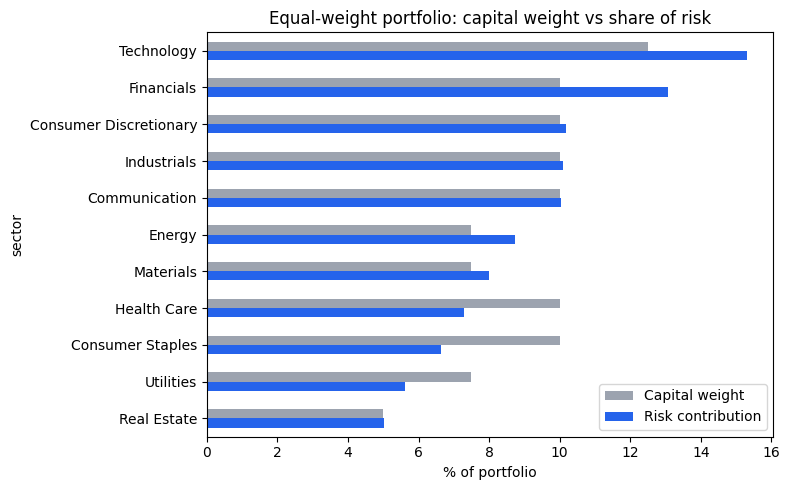

In [5]:
def risk_contributions(w, cov):
    vol = np.sqrt(w @ cov @ w)
    mrc = cov @ w / vol
    crc = w * mrc
    return vol, mrc, crc

cov_full = rets.cov().values * TRADING_DAYS
w_eq = np.ones(len(tickers)) / len(tickers)
vol_eq, mrc, crc = risk_contributions(w_eq, cov_full)
attr = pd.DataFrame({"sector": sector, "weight": w_eq, "marginal_risk": mrc, "risk_share": crc / vol_eq}, index=tickers)
print(f"Equal-weight portfolio annualised volatility: {vol_eq:.1%}\n")

by_sector = attr.groupby("sector")[["weight", "risk_share"]].sum().sort_values("risk_share", ascending=False)
by_sector["risk_minus_weight"] = by_sector.risk_share - by_sector.weight
print((by_sector * 100).round(1).to_string(), "\n")
print("Top 5 stocks by share of portfolio risk:")
print((attr.sort_values("risk_share", ascending=False).head(5)[["sector", "weight", "risk_share"]]
       .assign(weight=lambda d: (d.weight * 100).round(1), risk_share=lambda d: (d.risk_share * 100).round(1))).to_string())
attr.to_csv(f"{OUT}/risk_attribution_by_stock.csv"); by_sector.to_csv(f"{OUT}/risk_attribution_by_sector.csv")

ax = by_sector[["weight", "risk_share"]].mul(100).plot.barh(figsize=(8, 5), color=["#9ca3af", "#2563eb"])
ax.set_xlabel("% of portfolio"); ax.set_title("Equal-weight portfolio: capital weight vs share of risk"); ax.invert_yaxis()
ax.legend(["Capital weight", "Risk contribution"]); plt.tight_layout(); plt.savefig(f"{OUT}/weight_vs_risk_by_sector.png", dpi=150); plt.show()

## 3. Hidden concentration
**Effective number of bets (ENB)** (Meucci, 2009): break the portfolio's risk into independent sources (the principal components of Σ), then measure how evenly the risk is spread across them. ENB = 40 would mean 40 truly independent bets. A low ENB means the "40 stocks" are really just a few bets.

**Hierarchical clustering:** group stocks by how similarly they actually move, using the distance d = √(½(1 − ρ)), and compare these data-driven clusters with official sector labels.

Holdings: 40 | Effective number of bets: 1.10
Share of risk from the single largest risk factor (the 'market'): 98.4%

11 correlation clusters vs 11 sectors: adjusted Rand index = 0.23 (1 = identical, 0 = unrelated)
3 of 11 clusters mix stocks from different sectors

         n_stocks  weight  risk_share                                                                                sectors
cluster                                                                                                                     
2              13    32.5        37.5  Communication, Consumer Discretionary, Financials, Industrials, Materials, Technology
4               6    15.0        18.7                                      Communication, Consumer Discretionary, Technology
7               9    22.5        17.7                       Consumer Discretionary, Consumer Staples, Real Estate, Utilities
1               3     7.5         8.7                                                                      

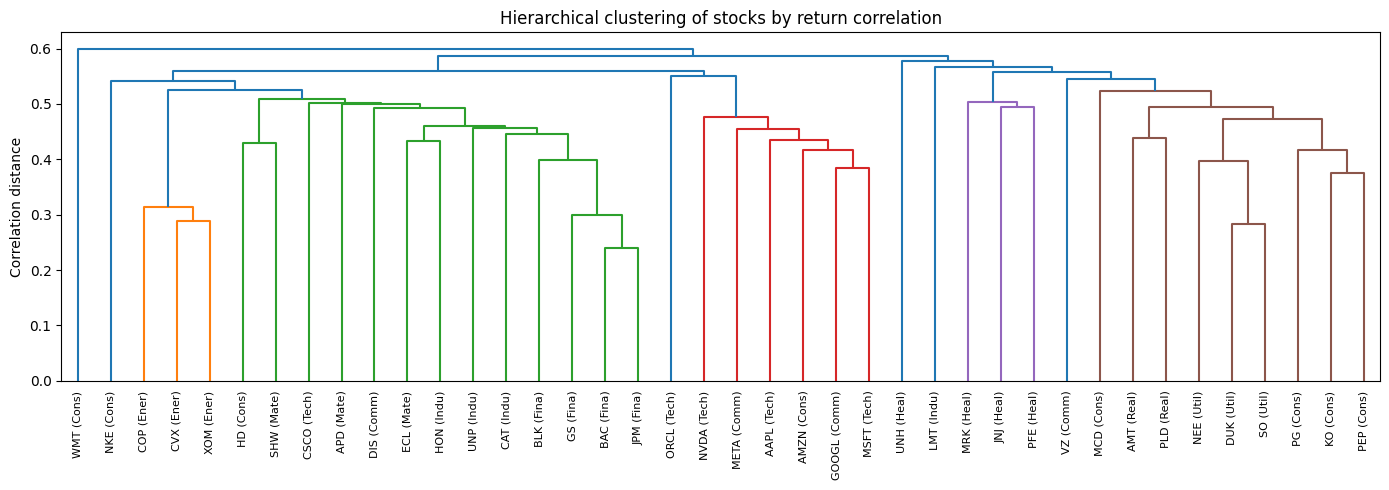

In [6]:
def effective_number_of_bets(w, cov):
    lam, E = np.linalg.eigh(cov)
    contrib = (E.T @ w) ** 2 * lam
    p = contrib / contrib.sum(); p = p[p > 1e-12]
    return float(np.exp(-(p * np.log(p)).sum())), contrib[::-1] / contrib.sum()

enb_eq, pc_share = effective_number_of_bets(w_eq, cov_full)
print(f"Holdings: {len(tickers)} | Effective number of bets: {enb_eq:.2f}")
print(f"Share of risk from the single largest risk factor (the 'market'): {pc_share[0]:.1%}")

corr = rets.corr()
dist = np.sqrt(0.5 * (1 - corr.values)); np.fill_diagonal(dist, 0)
Z = linkage(squareform(dist, checks=False), "average")
k = sector.nunique()
clusters = pd.Series(fcluster(Z, k, criterion="maxclust"), index=tickers, name="cluster")
ari = adjusted_rand_score(sector, clusters)
mixed = sum(sector[clusters == c].nunique() > 1 for c in clusters.unique())
print(f"\n{k} correlation clusters vs {k} sectors: adjusted Rand index = {ari:.2f} (1 = identical, 0 = unrelated)")
print(f"{mixed} of {clusters.nunique()} clusters mix stocks from different sectors\n")

cl = attr.assign(cluster=clusters).groupby("cluster").agg(
    n_stocks=("weight", "size"), weight=("weight", "sum"), risk_share=("risk_share", "sum"),
    sectors=("sector", lambda s: ", ".join(sorted(s.unique()))))
cl = cl.sort_values("risk_share", ascending=False)
cl.to_csv(f"{OUT}/clusters.csv")
print((cl.assign(weight=(cl.weight * 100).round(1), risk_share=(cl.risk_share * 100).round(1))).to_string())
top = cl.iloc[0]
print(f"\nLargest hidden cluster: {top.n_stocks} stocks = {top.weight:.0%} of capital but {top.risk_share:.0%} of risk")

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, labels=[f"{t} ({sector[t][:4]})" for t in tickers], leaf_rotation=90, ax=ax, color_threshold=Z[-(k - 1), 2])
ax.set_title("Hierarchical clustering of stocks by return correlation"); ax.set_ylabel("Correlation distance")
plt.tight_layout(); plt.savefig(f"{OUT}/dendrogram.png", dpi=150); plt.show()

## 4. Out-of-sample test: sample covariance vs Ledoit-Wolf shrinkage
With 40 stocks we estimate 820 covariances from one year of data, so the **sample covariance is noisy**. Optimisers exploit that noise and **underestimate risk**. **Ledoit-Wolf** shrinks the estimate towards a structured target to reduce estimation error.

**Test:** each month, estimate Σ from the previous 252 days, build the minimum-variance portfolio, then compare its **forecast** volatility with the **realised** volatility over the next month. A realised/forecast ratio of 1.0 is perfect; above 1 means risk was underestimated.

In [7]:
def estimate_cov(window, method):
    if method == "Ledoit-Wolf":
        return LedoitWolf().fit(window.values).covariance_ * TRADING_DAYS
    return np.cov(window.values, rowvar=False) * TRADING_DAYS

def min_variance(cov):
    n = len(cov)
    res = minimize(lambda w: w @ cov @ w, np.ones(n) / n, jac=lambda w: 2 * cov @ w, method="SLSQP",
                   bounds=[(0, 1)] * n, constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
                   options={"ftol": 1e-12, "maxiter": 500})
    w = np.clip(res.x, 0, None); return w / w.sum()

LOOKBACK, HOLD = 252, 21
rebal_idx = list(range(LOOKBACK, len(rets) - HOLD, HOLD))
fc = []
for i in rebal_idx:
    window, nxt = rets.iloc[i - LOOKBACK:i], rets.iloc[i:i + HOLD]
    for m in ["Sample", "Ledoit-Wolf"]:
        cov = estimate_cov(window, m); w = min_variance(cov)
        fc.append(dict(date=rets.index[i], method=m, forecast=np.sqrt(w @ cov @ w),
                       realised=(nxt.values @ w).std() * np.sqrt(TRADING_DAYS)))
fc = pd.DataFrame(fc)
fc["ratio"] = fc.realised / fc.forecast
cov_test = fc.groupby("method").agg(mean_forecast_vol=("forecast", "mean"), mean_realised_vol=("realised", "mean"),
                                    median_realised_to_forecast=("ratio", "median"))
cov_test.to_csv(f"{OUT}/covariance_forecast_test.csv")
print(cov_test.round(3).to_string())

             mean_forecast_vol  mean_realised_vol  median_realised_to_forecast
method                                                                        
Ledoit-Wolf              0.111              0.110                        0.866
Sample                   0.112              0.112                        0.855


## 5. Backtest: Equal-weight vs Minimum-Variance vs Hierarchical Risk Parity
**HRP** (López de Prado, 2016) uses the clustering idea directly: it orders stocks by correlation, then splits capital top-down between clusters in inverse proportion to their risk. Unlike minimum-variance, it **never inverts the covariance matrix**, so it's much less sensitive to estimation noise.

All strategies rebalance monthly, use only past data (no look-ahead), and use the Ledoit-Wolf covariance. Sharpe ratios assume a 0% risk-free rate, and transaction costs are ignored (turnover is reported instead).

Out-of-sample period: 2017-01-04 to 2025-12-10

                  ann_return  ann_vol  sharpe  max_drawdown  avg_monthly_turnover  avg_ENB
Equal-weight           0.170    0.171   1.000        -0.330                 0.000    1.497
Minimum-variance       0.114    0.144   0.819        -0.294                 0.128    6.132
HRP                    0.142    0.156   0.929        -0.310                 0.110    2.460


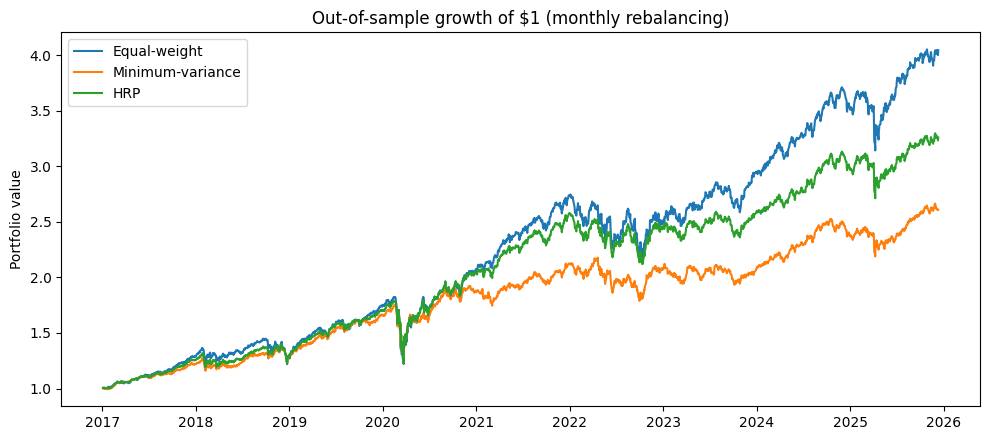

In [8]:
def hrp(cov):
    sd = np.sqrt(np.diag(cov)); corr_ = cov / np.outer(sd, sd)
    d = np.sqrt(np.clip(0.5 * (1 - corr_), 0, None)); np.fill_diagonal(d, 0)
    order = list(leaves_list(linkage(squareform(d, checks=False), "single")))
    def cluster_var(idx):
        sub = cov[np.ix_(idx, idx)]; ivp = 1 / np.diag(sub); ivp /= ivp.sum()
        return ivp @ sub @ ivp
    w = np.ones(len(cov)); parts = [order]
    while parts:
        parts = [p[a:b] for p in parts for a, b in ((0, len(p) // 2), (len(p) // 2, len(p))) if len(p) > 1]
        for j in range(0, len(parts), 2):
            left, right = parts[j], parts[j + 1]
            vl, vr = cluster_var(left), cluster_var(right)
            alpha = 1 - vl / (vl + vr)
            w[left] *= alpha; w[right] *= 1 - alpha
    return w / w.sum()

strategies = {"Equal-weight": lambda cov: np.ones(len(cov)) / len(cov), "Minimum-variance": min_variance, "HRP": hrp}
daily = {s: [] for s in strategies}; turnover = {s: [] for s in strategies}; prev = {s: None for s in strategies}
enb_hist = {s: [] for s in strategies}
for i in rebal_idx:
    cov = estimate_cov(rets.iloc[i - LOOKBACK:i], "Ledoit-Wolf"); nxt = rets.iloc[i:i + HOLD]
    for s, f in strategies.items():
        w = f(cov)
        daily[s].append(pd.Series(nxt.values @ w, index=nxt.index))
        if prev[s] is not None: turnover[s].append(0.5 * np.abs(w - prev[s]).sum())
        prev[s] = w; enb_hist[s].append(effective_number_of_bets(w, cov)[0])

def perf(r):
    cum = (1 + r).cumprod()
    return dict(ann_return=cum.iloc[-1] ** (TRADING_DAYS / len(r)) - 1, ann_vol=r.std() * np.sqrt(TRADING_DAYS),
                sharpe=r.mean() / r.std() * np.sqrt(TRADING_DAYS), max_drawdown=(cum / cum.cummax() - 1).min())

bt = {s: pd.concat(v) for s, v in daily.items()}
summary = pd.DataFrame({s: {**perf(r), "avg_monthly_turnover": np.mean(turnover[s]), "avg_ENB": np.mean(enb_hist[s])}
                        for s, r in bt.items()}).T
summary.to_csv(f"{OUT}/backtest_summary.csv")
print(f"Out-of-sample period: {bt['HRP'].index[0].date()} to {bt['HRP'].index[-1].date()}\n")
print(summary.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
for s, r in bt.items(): ax.plot((1 + r).cumprod(), label=s)
ax.set_title("Out-of-sample growth of $1 (monthly rebalancing)"); ax.set_ylabel("Portfolio value"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/backtest.png", dpi=150); plt.show()

## 6. Your resume numbers
These are real results from real data, so you can defend every one.

In [9]:
s, c = summary, cov_test
print(f"Universe: {len(tickers)} S&P 500 stocks, {sector.nunique()} sectors, {len(rets)} trading days")
print(f"Equal-weight portfolio: ENB = {enb_eq:.1f} independent bets out of {len(tickers)} holdings; "
      f"largest factor = {pc_share[0]:.0%} of risk")
print(f"Largest hidden cluster: {top.n_stocks} stocks, {top.weight:.0%} of capital -> {top.risk_share:.0%} of risk; "
      f"{mixed} of {clusters.nunique()} clusters cut across sectors (ARI vs sectors = {ari:.2f})")
print(f"Min-variance realised/forecast vol ratio: sample {c.loc['Sample','median_realised_to_forecast']:.2f} "
      f"vs Ledoit-Wolf {c.loc['Ledoit-Wolf','median_realised_to_forecast']:.2f} (1.00 = perfect)")
print(f"Sharpe: HRP {s.loc['HRP','sharpe']:.2f} | Min-var {s.loc['Minimum-variance','sharpe']:.2f} | Equal-weight {s.loc['Equal-weight','sharpe']:.2f}")
print(f"Max drawdown: HRP {s.loc['HRP','max_drawdown']:.1%} vs Equal-weight {s.loc['Equal-weight','max_drawdown']:.1%}")
print(f"Monthly turnover: HRP {s.loc['HRP','avg_monthly_turnover']:.1%} vs Min-var {s.loc['Minimum-variance','avg_monthly_turnover']:.1%}")

Universe: 40 S&P 500 stocks, 11 sectors, 2512 trading days
Equal-weight portfolio: ENB = 1.1 independent bets out of 40 holdings; largest factor = 98% of risk
Largest hidden cluster: 13 stocks, 32% of capital -> 37% of risk; 3 of 11 clusters cut across sectors (ARI vs sectors = 0.23)
Min-variance realised/forecast vol ratio: sample 0.86 vs Ledoit-Wolf 0.87 (1.00 = perfect)
Sharpe: HRP 0.93 | Min-var 0.82 | Equal-weight 1.00
Max drawdown: HRP -31.0% vs Equal-weight -33.0%
Monthly turnover: HRP 11.0% vs Min-var 12.8%
